# Rain in Australia — Gradient Boosting (LightGBM + CatBoost)

**Task:** predict `RainTomorrow` with the same data cleaning, chronological split and expanding-window CV as in `EDA.ipynb`.

**Plan**
1. Naive baseline: *tomorrow = today*.
2. Feature engineering (`src/features.py`) and an ablation showing what each feature family adds.
3. LightGBM and CatBoost on time-based CV, blend weight and decision threshold chosen on out-of-fold predictions only.
4. One final evaluation on the held-out test year (2016-07-01 → 2017-06-25).
5. Error analysis, feature importance, and why many public notebooks on this dataset report ~95% accuracy.

Full run takes ~15–25 minutes on a laptop; all outputs are saved in the notebook.

## 1. Setup

In [1]:
import json
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "models" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import catboost
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from catboost import CatBoostClassifier
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

from src.data_prep import CATEGORICAL_FEATURES, FEATURES, SEED, TARGET, load_clean, split_train_test, time_cv_splits
from src.features import feature_list, load_features

RESULTS = ROOT / "models" / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.precision", 4)
np.random.seed(SEED)
print(f"lightgbm {lgb.__version__} | catboost {catboost.__version__} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}")

lightgbm 4.7.0 | catboost 1.2.10 | scikit-learn 1.9.1 | pandas 3.1.0


## 2. Data and features

`load_features()` applies the cleaning from `src/data_prep.py` and then builds features. Every feature uses only **today's or earlier** observations, so nothing from the target day leaks in. Features are computed before rows with a missing target are dropped, so a day without a label can still serve as "yesterday" for the next day.

In [2]:
t0 = time.time()
df = load_features()
feats = feature_list(df)
train, gap, test = split_train_test(df)
folds = time_cv_splits(train["Date"])
X, y = train[feats], train[TARGET]
Xt, yt = test[feats], test[TARGET]
print(f"Built {len(feats)} features in {time.time() - t0:.0f}s | train {len(train):,} rows | test {len(test):,} rows | rain share in test {yt.mean():.1%}")

Built 141 features in 4s | train 124,858 rows | test 17,286 rows | rain share in test 23.2%


In [3]:
def family(c):
    if c.startswith(("Near_", "West_")) or c in ("Lat", "Lon", "Hum_vsNear", "Press_vsNear"):
        return "5. Neighbour stations"
    if c.startswith("Nat_") or c.endswith("_vsNat"):
        return "4. National (same day)"
    if any(k in c for k in ("_lag", "_diff1", "_sum", "RainDays", "_mean", "_anom", "DryStreak")):
        return "3. Station history"
    if c in FEATURES:
        return "1. Original"
    return "2. Same-day derived"

FAMILY_NOTES = {
    "1. Original": "raw columns from the dataset",
    "2. Same-day derived": "season (day-of-year sin/cos), 9am→3pm changes, temperature range, wind as vectors",
    "3. Station history": "lags 1–3 days, 1-day changes, 3/7/14/30-day rain sums and means, dry streak, 7-day anomalies",
    "4. National (same day)": "mean/std across all stations on the same date and the station's deviation from it",
    "5. Neighbour stations": "distance-weighted average of nearby (~300 km) and western (~700 km) stations on the same date",
}
fam = pd.Series({c: family(c) for c in feats})
display(pd.DataFrame({
    "n_features": fam.value_counts().sort_index(),
    "what": pd.Series(FAMILY_NOTES),
    "examples": fam.groupby(fam).apply(lambda s: ", ".join(s.index[:4])),
}))

,n_features,what,examples
1. Original,21,raw columns from the dataset,"Location, MinTemp, MaxTemp, Rainfall"
2. Same-day derived,21,"season (day-of-year sin/cos), 9am→3pm changes,...","DoySin, DoyCos, PressureDelta, HumidityDelta"
3. Station history,51,"lags 1–3 days, 1-day changes, 3/7/14/30-day ra...","Rainfall_lag1, Rainfall_lag2, Rainfall_lag3, R..."
4. National (same day),14,mean/std across all stations on the same date ...,"Nat_Humidity3pm_mean, Nat_Humidity3pm_std, Nat..."
5. Neighbour stations,34,distance-weighted average of nearby (~300 km) ...,"Near_Rainfall, West_Rainfall, Near_RainToday, ..."


## 3. Helpers

In [4]:
PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=31, min_child_samples=100,
              feature_fraction=0.5, bagging_fraction=0.8, bagging_freq=1, lambda_l2=5.0, verbose=-1, n_jobs=-1)
N_ROUNDS = 1100
CAT_PARAMS = dict(iterations=1500, learning_rate=0.06, depth=7, l2_leaf_reg=5, verbose=0, thread_count=-1,
                  train_dir=str(RESULTS / "catboost_info"))


def as_lgb(X_tr, X_pr):
    X_tr, X_pr = X_tr.copy(), X_pr.copy()
    for c in [c for c in CATEGORICAL_FEATURES if c in X_tr]:
        dtype = pd.CategoricalDtype(sorted(set(X_tr[c].dropna()) | set(X_pr[c].dropna())))
        X_tr[c], X_pr[c] = X_tr[c].astype(dtype), X_pr[c].astype(dtype)
    return X_tr, X_pr


def as_cat(X):
    X = X.copy()
    for c in CATEGORICAL_FEATURES:
        X[c] = X[c].fillna("Missing").astype(str)
    return X


def fit_lgb(X_tr, y_tr, X_pr, seeds=(SEED,)):
    X_tr, X_pr = as_lgb(X_tr, X_pr)
    models = [lgb.train({**PARAMS, "seed": s}, lgb.Dataset(X_tr, y_tr), N_ROUNDS) for s in seeds]
    return np.mean([m.predict(X_pr) for m in models], axis=0), models


def fit_cat(X_tr, y_tr, X_pr, seeds=(SEED,)):
    models = [CatBoostClassifier(**CAT_PARAMS, cat_features=CATEGORICAL_FEATURES, random_seed=s).fit(as_cat(X_tr), y_tr)
              for s in seeds]
    return np.mean([m.predict_proba(as_cat(X_pr))[:, 1] for m in models], axis=0), models


def cv_predict(fit, cols):
    oof = np.zeros(len(train))
    for tr, va in folds:
        oof[va] = fit(X.iloc[tr][cols], y.iloc[tr], X.iloc[va][cols])[0]
    return oof


VAL_IDX = np.concatenate([va for _, va in folds])
FOLD_ID = np.concatenate([np.full(len(va), k) for k, (_, va) in enumerate(folds, 1)])


def fold_scores(oof):
    return pd.DataFrame([{
        "fold": k, "val_period": f"{train['Date'].iloc[va].min():%Y-%m} → {train['Date'].iloc[va].max():%Y-%m}",
        "roc_auc": roc_auc_score(y.iloc[va], oof[va]), "pr_auc": average_precision_score(y.iloc[va], oof[va]),
    } for k, (_, va) in enumerate(folds, 1)])


def scores(y_true, p, t):
    pred = p > t
    return dict(roc_auc=roc_auc_score(y_true, p), pr_auc=average_precision_score(y_true, p), f1=f1_score(y_true, pred),
                precision=precision_score(y_true, pred), recall=recall_score(y_true, pred))


THRESHOLDS = np.round(np.arange(0.10, 0.71, 0.01), 2)

## 4. Baseline: "tomorrow will be like today"

Any model has to beat the simplest rule: predict rain tomorrow if it rained today. Accuracy is misleading here (always saying "no rain" already gives ~78%), so we report **F1, precision and recall for the rain class**, plus ROC-AUC / PR-AUC for the models.

In [5]:
def baseline_row(part, name):
    p = part["RainToday"].fillna(0)
    return {"split": name, "f1": f1_score(part[TARGET], p), "precision": precision_score(part[TARGET], p),
            "recall": recall_score(part[TARGET], p), "accuracy": (p == part[TARGET]).mean()}

baseline = pd.DataFrame([baseline_row(train.iloc[va], f"CV fold {k}") for k, (_, va) in enumerate(folds, 1)]
                        + [baseline_row(test, "TEST")])
display(baseline)

,split,f1,precision,recall,accuracy
0,CV fold 1,0.4458,0.4491,0.4425,0.7730
1,CV fold 2,0.4610,0.4647,0.4573,0.7675
2,CV fold 3,0.4326,0.4355,0.4298,0.7655
3,CV fold 4,0.4456,0.4484,0.4428,0.7670
4,TEST,0.4462,0.4485,0.4438,0.7446


## 5. Feature ablation (LightGBM, time-based CV)

Each step adds one feature family on top of the previous ones. Same model, same folds, one seed — so differences come from the features only.

In [6]:
steps = sorted(fam.unique())
ablation, oof_by_step = [], {}
for i, step in enumerate(steps):
    cols = fam.index[fam.isin(steps[: i + 1])].tolist()
    t0 = time.time()
    oof = cv_predict(fit_lgb, cols)
    oof_by_step[step] = oof
    fs = fold_scores(oof)
    ablation.append({"features": ("" if i == 0 else "+ ") + step[3:], "n_features": len(cols),
                     "cv_roc_auc": fs.roc_auc.mean(), "cv_pr_auc": fs.pr_auc.mean(),
                     **{f"fold{k}": v for k, v in zip(fs.fold, fs.roc_auc)}})
    print(f"{step:26s} {len(cols):3d} features  ROC-AUC={fs.roc_auc.mean():.4f}  ({time.time() - t0:.0f}s)")
ablation = pd.DataFrame(ablation)
display(ablation)

1. Original                 21 features  ROC-AUC=0.8987  (54s)


2. Same-day derived         42 features  ROC-AUC=0.9018  (63s)


3. Station history          93 features  ROC-AUC=0.9024  (98s)


4. National (same day)     107 features  ROC-AUC=0.9070  (100s)


5. Neighbour stations      141 features  ROC-AUC=0.9165  (117s)


,features,n_features,cv_roc_auc,cv_pr_auc,fold1,fold2,fold3,fold4
0,Original,21,0.8987,0.7484,0.8956,0.9039,0.9001,0.8954
1,+ Same-day derived,42,0.9018,0.7555,0.8989,0.9067,0.9039,0.8976
2,+ Station history,93,0.9024,0.7559,0.8986,0.9064,0.9066,0.8981
3,+ National (same day),107,0.9070,0.7639,0.9035,0.9109,0.9102,0.9036
4,+ Neighbour stations,141,0.9165,0.7820,0.9121,0.9197,0.9188,0.9155


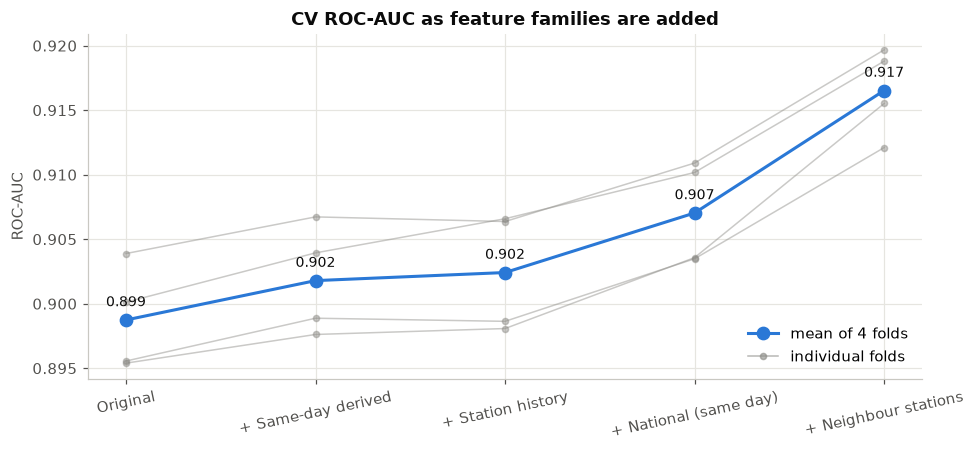

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
xs = np.arange(len(ablation))
for k in range(1, len(folds) + 1):
    ax.plot(xs, ablation[f"fold{k}"], color=GRAY, lw=1, alpha=0.45, marker="o", ms=4, zorder=1)
ax.plot(xs, ablation["cv_roc_auc"], color=BLUE, marker="o", ms=8, zorder=3, label="mean of 4 folds")
for x, v in zip(xs, ablation["cv_roc_auc"]):
    ax.annotate(f"{v:.3f}", (x, v), textcoords="offset points", xytext=(0, 9), ha="center", color=INK, fontsize=9)
ax.plot([], [], color=GRAY, lw=1, alpha=0.6, marker="o", ms=4, label="individual folds")
ax.set_xticks(xs, ablation["features"], rotation=12)
ax.set(title="CV ROC-AUC as feature families are added", ylabel="ROC-AUC")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(RESULTS / "ablation.png", dpi=150)
plt.show()

**Takeaways**
- Even with only the original 21 columns, LightGBM reaches CV ROC-AUC **0.899** — already far above the baseline.
- Same-day derived features and station history add a little each (+0.003 and +0.001). Most of yesterday's information is already reflected in today's humidity and pressure.
- **National same-day features** (+0.004) and especially **neighbour stations** (+0.010) give the biggest gains. Rain comes with weather systems that cover hundreds of kilometres; a single station sees only one point of that system.
- The improvement is consistent: every fold goes up at every step, so it is not noise from one lucky year.

## 6. LightGBM vs CatBoost and the blend

LightGBM out-of-fold predictions on all features come from the last ablation step. CatBoost is trained on the same folds. The blend weight is chosen on out-of-fold ROC-AUC — the test set is not touched.

In [8]:
oof_lgb = oof_by_step[steps[-1]]
t0 = time.time()
oof_cat = cv_predict(fit_cat, feats)
print(f"CatBoost CV done in {time.time() - t0:.0f}s")

weights = np.round(np.arange(0, 1.01, 0.1), 1)
w_auc = [roc_auc_score(y.iloc[VAL_IDX], ((1 - w) * oof_lgb + w * oof_cat)[VAL_IDX]) for w in weights]
W_CAT = float(weights[int(np.argmax(w_auc))])
oof_blend = (1 - W_CAT) * oof_lgb + W_CAT * oof_cat

cv_table = pd.concat({"LightGBM": fold_scores(oof_lgb), "CatBoost": fold_scores(oof_cat),
                      f"Blend (w_cat={W_CAT})": fold_scores(oof_blend)}, names=["model"]).reset_index(0)
display(cv_table.pivot(index=["fold", "val_period"], columns="model", values="roc_auc"))
display(cv_table.groupby("model")[["roc_auc", "pr_auc"]].mean())

CatBoost CV done in 1411s


,model,Blend (w_cat=0.4),CatBoost,LightGBM
fold,val_period,,,
1,2012-07 → 2013-06,0.9132,0.9103,0.9121
2,2013-07 → 2014-06,0.9210,0.9183,0.9197
3,2014-07 → 2015-06,0.9197,0.9170,0.9188
4,2015-07 → 2016-06,0.9165,0.9135,0.9155


,roc_auc,pr_auc
model,,
Blend (w_cat=0.4),0.9176,0.7840
CatBoost,0.9148,0.7776
LightGBM,0.9165,0.7820


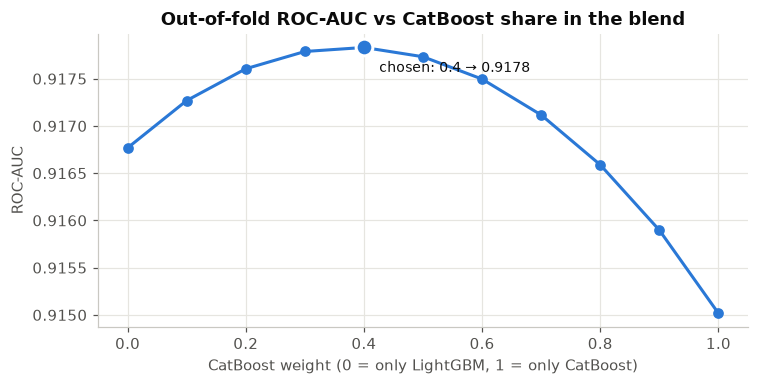

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(weights, w_auc, color=BLUE, marker="o", ms=6)
ax.scatter([W_CAT], [max(w_auc)], s=120, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
ax.annotate(f"chosen: {W_CAT} → {max(w_auc):.4f}", (W_CAT, max(w_auc)), textcoords="offset points",
            xytext=(10, -16), color=INK, fontsize=9)
ax.set(title="Out-of-fold ROC-AUC vs CatBoost share in the blend", xlabel="CatBoost weight (0 = only LightGBM, 1 = only CatBoost)",
       ylabel="ROC-AUC")
fig.tight_layout()
plt.show()

**Takeaways**
- LightGBM is slightly stronger than CatBoost on every fold (0.9165 vs 0.9147 mean ROC-AUC).
- The blend beats both models on **every** fold (mean 0.9175). The two models make partly different errors, so averaging them helps.
- The gain is small (+0.001 ROC-AUC). The curve is flat between 0.2 and 0.5, so the exact weight does not matter much.

## 7. Decision threshold

Models output a probability; we still need a cut-off for "rain / no rain". With only ~22% rainy days, 0.5 is too conservative. We pick the threshold that maximises F1 on the **out-of-fold** predictions and then freeze it for the test.

,f1,precision,recall
threshold,,,
0.30,0.7028,0.6591,0.7528
0.33,0.7028,0.6772,0.7304
0.40,0.6964,0.7172,0.6768
0.50,0.6764,0.7717,0.6020


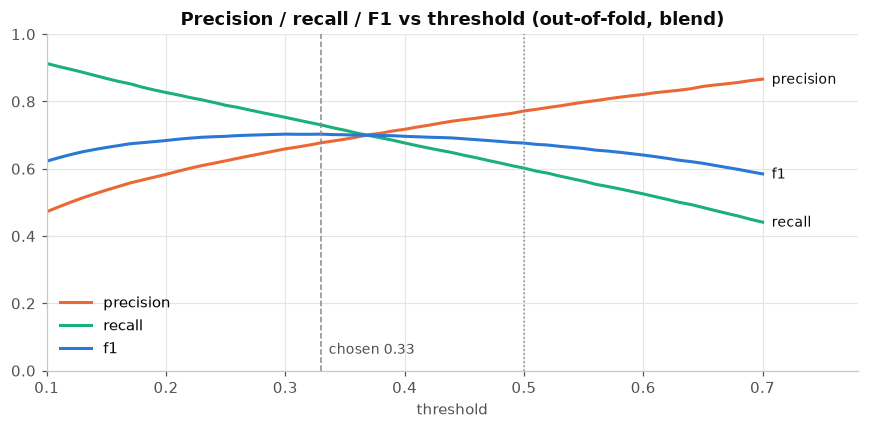

In [10]:
yv, pv = y.iloc[VAL_IDX].to_numpy(), oof_blend[VAL_IDX]
curve = pd.DataFrame([{"threshold": t, "f1": f1_score(yv, pv > t), "precision": precision_score(yv, pv > t),
                       "recall": recall_score(yv, pv > t)} for t in THRESHOLDS])
THRESHOLD = float(curve.loc[curve.f1.idxmax(), "threshold"])
display(curve.set_index("threshold").loc[[0.3, THRESHOLD, 0.4, 0.5]].drop_duplicates())

fig, ax = plt.subplots(figsize=(8, 4))
for col, color in [("precision", ORANGE), ("recall", AQUA), ("f1", BLUE)]:
    ax.plot(curve.threshold, curve[col], color=color, label=col)
    ax.annotate(col, (curve.threshold.iloc[-1], curve[col].iloc[-1]), textcoords="offset points", xytext=(6, -3),
                color=INK, fontsize=9)
ax.axvline(THRESHOLD, color=GRAY, ls="--", lw=1)
ax.annotate(f"chosen {THRESHOLD:.2f}", (THRESHOLD, 0.05), textcoords="offset points", xytext=(5, 0), color=MUTED, fontsize=9)
ax.axvline(0.5, color=GRAY, ls=":", lw=1)
ax.set(title="Precision / recall / F1 vs threshold (out-of-fold, blend)", xlabel="threshold", ylim=(0, 1), xlim=(0.1, 0.78))
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(RESULTS / "threshold.png", dpi=150)
plt.show()

**Takeaways**
- F1 peaks at threshold **0.33** (out-of-fold F1 0.702 vs 0.675 at the default 0.5).
- The F1 curve is flat between ~0.25 and ~0.45, so the choice is robust.
- The threshold is a business decision: an airport or an outdoor event might prefer higher recall (lower threshold), a farmer deciding whether to skip irrigation might prefer higher precision.

## 8. Final models and test evaluation

Final models are trained on the whole training period (2008 → 2016-06): LightGBM averaged over 3 seeds, CatBoost with 1 seed. The blend weight and threshold come from CV above. This is the only time the test set is used.

In [11]:
t0 = time.time()
p_lgb, lgb_models = fit_lgb(X, y, Xt, seeds=(SEED, SEED + 1, SEED + 2))
p_cat, cat_models = fit_cat(X, y, Xt)
p_blend = (1 - W_CAT) * p_lgb + W_CAT * p_cat
print(f"Final training done in {time.time() - t0:.0f}s")

base_pred = test["RainToday"].fillna(0)
final = pd.DataFrame({
    "Baseline (RainToday)": {"roc_auc": np.nan, "pr_auc": np.nan, "f1": f1_score(yt, base_pred),
                             "precision": precision_score(yt, base_pred), "recall": recall_score(yt, base_pred)},
    "LightGBM": scores(yt, p_lgb, THRESHOLD),
    "CatBoost": scores(yt, p_cat, THRESHOLD),
    "Blend": scores(yt, p_blend, THRESHOLD),
}).T
display(final)

summary = {**{k: float(v) for k, v in final.loc["Blend"].items()}, "threshold": THRESHOLD, "w_cat": W_CAT,
           "baseline_f1": float(final.loc["Baseline (RainToday)", "f1"]), "n_features": len(feats)}
(RESULTS / "results_boosting.json").write_text(json.dumps(summary, indent=2))
pd.DataFrame({"Date": test["Date"], "Location": test["Location"], "y_true": yt, "proba_lgb": p_lgb, "proba_cat": p_cat,
              "proba": p_blend, "pred": (p_blend > THRESHOLD).astype(int)}).to_csv(RESULTS / "predictions_boosting.csv", index=False)

Final training done in 571s


,roc_auc,pr_auc,f1,precision,recall
Baseline (RainToday),NaN,NaN,0.4462,0.4485,0.4438
LightGBM,0.9152,0.8008,0.7147,0.6918,0.7391
CatBoost,0.9135,0.7966,0.7170,0.6966,0.7386
Blend,0.9160,0.8023,0.7196,0.6975,0.7431


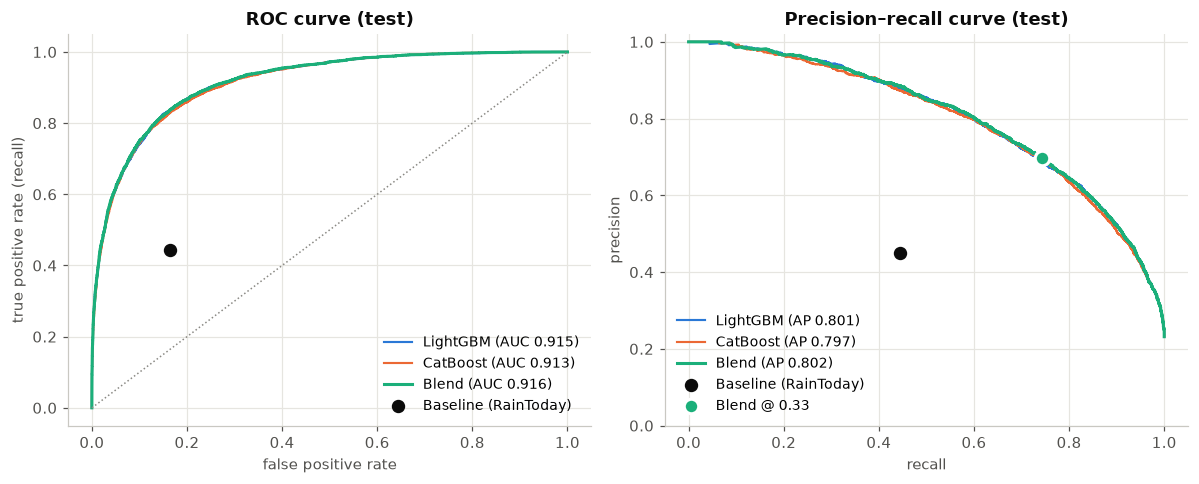

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, p, color in [("LightGBM", p_lgb, BLUE), ("CatBoost", p_cat, ORANGE), ("Blend", p_blend, AQUA)]:
    fpr, tpr, _ = roc_curve(yt, p)
    axes[0].plot(fpr, tpr, color=color, lw=2 if name == "Blend" else 1.4, label=f"{name} (AUC {roc_auc_score(yt, p):.3f})")
    prec, rec, _ = precision_recall_curve(yt, p)
    axes[1].plot(rec, prec, color=color, lw=2 if name == "Blend" else 1.4, label=f"{name} (AP {average_precision_score(yt, p):.3f})")
b = final.loc["Baseline (RainToday)"]
axes[0].plot([0, 1], [0, 1], color=GRAY, ls=":", lw=1)
fp_rate = ((base_pred == 1) & (yt == 0)).sum() / (yt == 0).sum()
axes[0].scatter([fp_rate], [b.recall], color=INK, s=60, zorder=3, label="Baseline (RainToday)")
axes[1].scatter([b.recall], [b.precision], color=INK, s=60, zorder=3, label="Baseline (RainToday)")
axes[1].scatter([final.loc["Blend", "recall"]], [final.loc["Blend", "precision"]], color=AQUA, s=90,
                edgecolor="white", linewidth=2, zorder=4, label=f"Blend @ {THRESHOLD:.2f}")
axes[0].set(title="ROC curve (test)", xlabel="false positive rate", ylabel="true positive rate (recall)")
axes[1].set(title="Precision–recall curve (test)", xlabel="recall", ylabel="precision", ylim=(0, 1.02))
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS / "roc_pr_test.png", dpi=150)
plt.show()

In [13]:
cm = confusion_matrix(yt, p_blend > THRESHOLD)
display(pd.DataFrame(cm, index=["actual: no rain", "actual: rain"], columns=["predicted: no rain", "predicted: rain"]))
tn, fp, fn, tp = cm.ravel()
print(f"Of {tp + fn:,} rainy days the model caught {tp:,} ({tp / (tp + fn):.0%}). "
      f"Of {tp + fp:,} rain alerts, {tp:,} were correct ({tp / (tp + fp):.0%}).")

,predicted: no rain,predicted: rain
actual: no rain,11989,1291
actual: rain,1029,2977


Of 4,006 rainy days the model caught 2,977 (74%). Of 4,268 rain alerts, 2,977 were correct (70%).


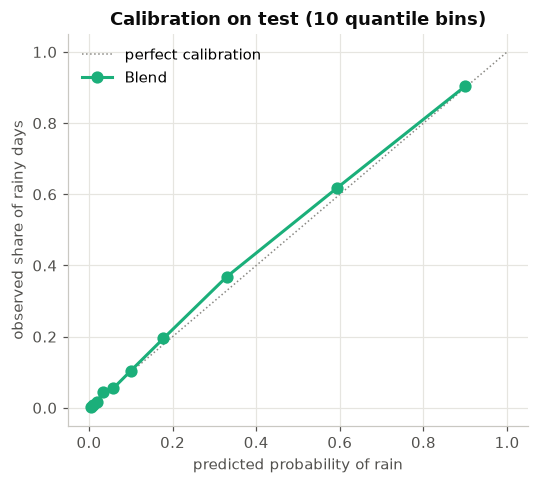

In [14]:
frac_pos, mean_pred = calibration_curve(yt, p_blend, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0, 1], [0, 1], color=GRAY, ls=":", lw=1, label="perfect calibration")
ax.plot(mean_pred, frac_pos, color=AQUA, marker="o", ms=7, label="Blend")
ax.set(title="Calibration on test (10 quantile bins)", xlabel="predicted probability of rain", ylabel="observed share of rainy days")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

**Takeaways (test year 2016-07 → 2017-06, never used for any decision above)**
- Blend: ROC-AUC **0.916**, PR-AUC **0.801**, F1 **0.718** (precision 0.697, recall 0.741). The baseline F1 is 0.446, so this is **+61%**.
- The model catches **74% of rainy days**, and **70% of its rain alerts are correct**.
- Test scores match CV (0.9175 / 0.702 F1 out-of-fold), so the model did not overfit the validation folds.
- The probabilities are well calibrated: when the model says 60%, it rains on about 60% of those days. In the 0.2–0.4 range it slightly underestimates rain.

## 9. What the model relies on

Gain importance from the 3 final LightGBM models: how much each feature reduced the loss in total, as a share of all gain. Grouped by feature family and top-20 individual features.

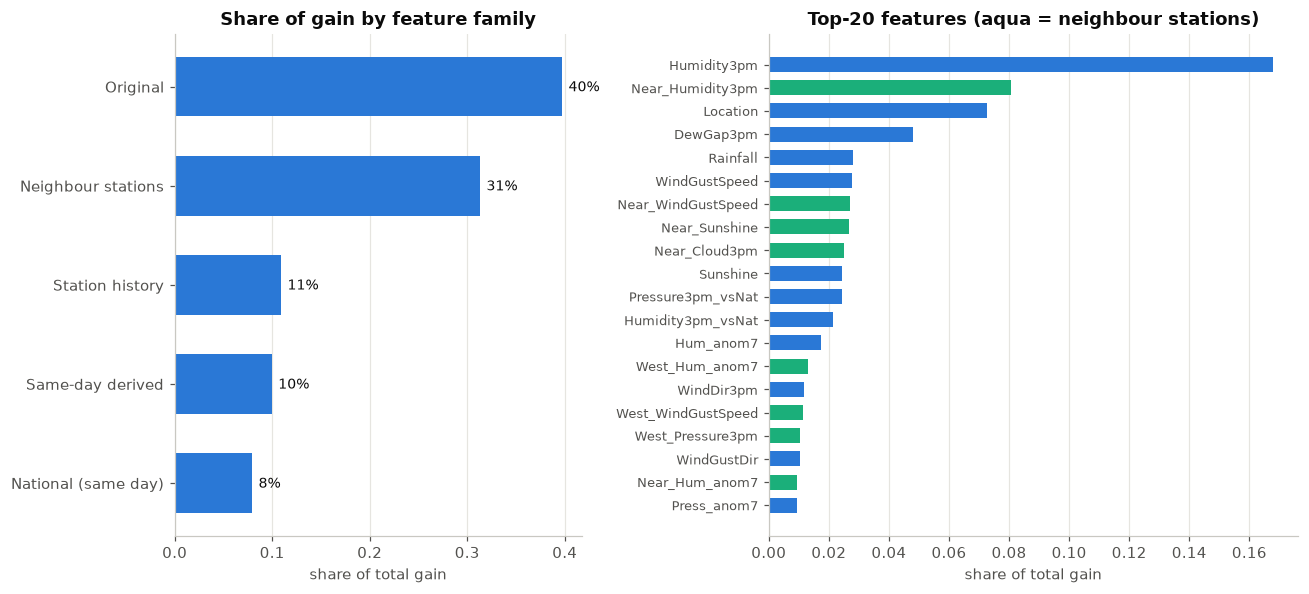

In [15]:
gain = pd.Series(np.mean([m.feature_importance("gain") for m in lgb_models], axis=0), index=feats)
gain = gain / gain.sum()
by_family = gain.groupby(fam).sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].barh([s[3:] for s in by_family.index], by_family.values, color=BLUE, height=0.6)
for i, v in enumerate(by_family.values):
    axes[0].annotate(f"{v:.0%}", (v, i), textcoords="offset points", xytext=(4, -3), color=INK, fontsize=9)
axes[0].set(title="Share of gain by feature family", xlabel="share of total gain")
top = gain.sort_values().tail(20)
axes[1].barh(top.index, top.values, color=[BLUE if fam[c] != "5. Neighbour stations" else AQUA for c in top.index], height=0.65)
axes[1].set(title="Top-20 features (aqua = neighbour stations)", xlabel="share of total gain")
axes[1].tick_params(axis="y", labelsize=8.5)
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(RESULTS / "feature_importance.png", dpi=150)
plt.show()

**Takeaways**
- **Afternoon humidity** (`Humidity3pm`) is by far the strongest single signal, followed by humidity at the **neighbouring stations**.
- Neighbour-station features take **31%** of the total gain with only 34 of 141 features. The model effectively looks at a weather map, not only at one station.
- `Location` matters: climates differ a lot between Darwin, Uluru and Hobart, and the same humidity means different things there.
- `DewGap3pm` (how close the air is to saturation) and the 7-day humidity / pressure anomalies are among the most useful engineered features.

## 10. Where the model is weaker

Test-set quality by station and by month. ROC-AUC per station is threshold-free; F1 uses the frozen threshold.

,rain_share,roc_auc,f1,n
Location,,,,
NorfolkIsland,0.3281,0.8339,0.6574,317.0
Hobart,0.2333,0.8523,0.5780,360.0
Newcastle,0.2601,0.8693,0.6667,346.0
GoldCoast,0.2326,0.8723,0.6776,344.0
Cairns,0.3416,0.8724,0.7331,322.0
Melbourne,0.2528,0.8729,0.7090,360.0
PearceRAAF,0.1932,0.9451,0.7606,352.0
Bendigo,0.2107,0.9451,0.7432,356.0
Nhil,0.1778,0.9465,0.7200,360.0


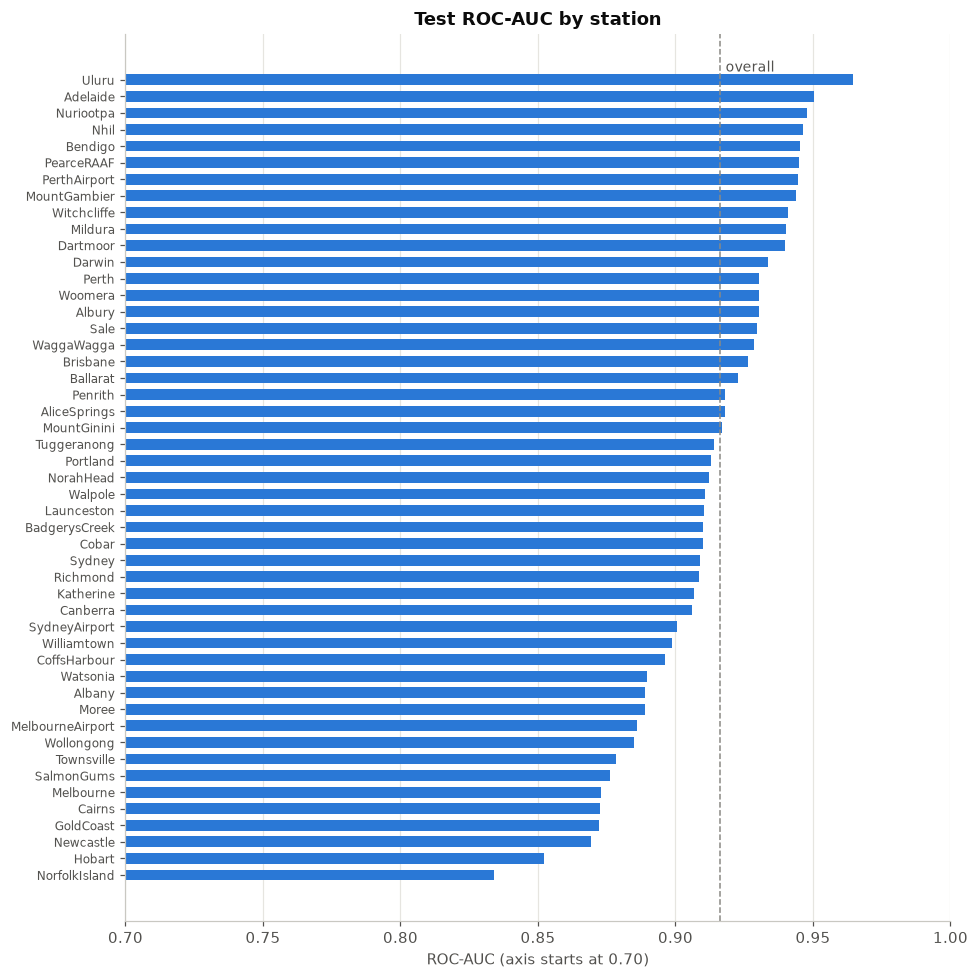

In [16]:
res = test[["Date", "Location"]].assign(y=yt.values, p=p_blend, pred=(p_blend > THRESHOLD).astype(int))
by_loc = res.groupby("Location").apply(lambda g: pd.Series({
    "rain_share": g.y.mean(), "roc_auc": roc_auc_score(g.y, g.p) if g.y.nunique() > 1 else np.nan,
    "f1": f1_score(g.y, g.pred, zero_division=0), "n": len(g)}), include_groups=False).sort_values("roc_auc")
display(pd.concat([by_loc.head(6), by_loc.tail(6)]))

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(by_loc.index, by_loc.roc_auc - 0.7, left=0.7, color=BLUE, height=0.65)
ax.axvline(roc_auc_score(yt, p_blend), color=GRAY, ls="--", lw=1)
ax.annotate("overall", (roc_auc_score(yt, p_blend), len(by_loc) - 0.5), textcoords="offset points", xytext=(4, 0),
            color=MUTED, fontsize=9)
ax.set(title="Test ROC-AUC by station", xlabel="ROC-AUC (axis starts at 0.70)", xlim=(0.7, 1.0))
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

,rain_share,roc_auc,f1,precision,recall
month,,,,,
1,0.1997,0.8944,0.6711,0.6581,0.6846
2,0.2112,0.9101,0.7185,0.7051,0.7324
3,0.2784,0.9192,0.7584,0.7241,0.7961
4,0.1978,0.9277,0.7182,0.7085,0.7282
5,0.1952,0.9245,0.7145,0.6993,0.7304
6,0.1579,0.9370,0.6849,0.6449,0.7302
7,0.3117,0.9120,0.7470,0.7137,0.7834
8,0.2779,0.9417,0.7661,0.7306,0.8052
9,0.3407,0.8924,0.7490,0.7288,0.7703


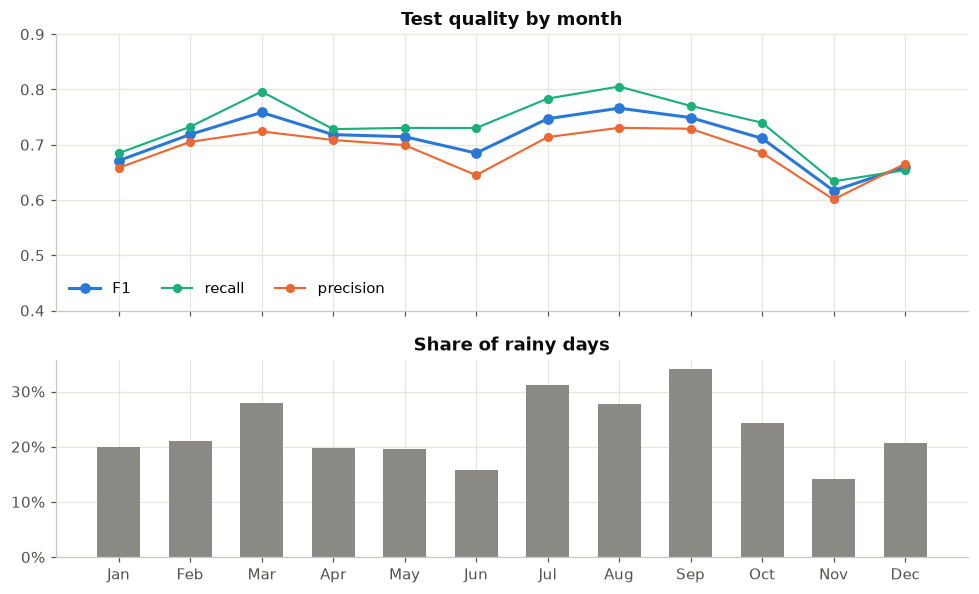

In [17]:
by_month = res.assign(month=res.Date.dt.month).groupby("month").apply(lambda g: pd.Series({
    "rain_share": g.y.mean(), "roc_auc": roc_auc_score(g.y, g.p), "f1": f1_score(g.y, g.pred),
    "precision": precision_score(g.y, g.pred), "recall": recall_score(g.y, g.pred)}), include_groups=False)
display(by_month)

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
axes[0].plot(by_month.index, by_month.f1, color=BLUE, marker="o", ms=6, label="F1")
axes[0].plot(by_month.index, by_month.recall, color=AQUA, marker="o", ms=5, lw=1.4, label="recall")
axes[0].plot(by_month.index, by_month.precision, color=ORANGE, marker="o", ms=5, lw=1.4, label="precision")
axes[0].set(title="Test quality by month", ylim=(0.4, 0.9))
axes[0].legend(ncol=3, loc="lower left")
axes[1].bar(by_month.index, by_month.rain_share, color=GRAY, width=0.6)
axes[1].set(title="Share of rainy days", xticks=range(1, 13),
            xticklabels=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
plt.show()

**Takeaways**
- **Weakest stations:** Norfolk Island (ROC-AUC 0.84) is an island ~1,400 km off the coast with no neighbours; Hobart is in Tasmania with only Launceston nearby; Cairns and Townsville are in the tropics, where showers are local. Melbourne also has notoriously changeable weather.
- **Strongest stations:** inland and southern stations such as Adelaide, Nhil and Uluru, where rain usually comes with large frontal systems that neighbours see first.
- **By season:** the model is best in winter (Jun–Aug ROC-AUC 0.94), when rain comes from fronts moving in from the west. It is weakest in late spring and summer (Nov–Jan, F1 ~0.62–0.65), when rain comes from local thunderstorms that are hard to predict a day ahead from daily station observations.

## 11. Why public notebooks report ~95% accuracy on this dataset

Many Kaggle notebooks on *Rain in Australia* report 0.95+ accuracy / ROC-AUC. A common recipe is to oversample the rainy class to 50/50 **before** a random `train_test_split`. Then copies of the same rainy day land in both train and test, and the test set no longer has the real 22% rain share.

Below the same Random Forest, on the same original features, is evaluated three ways.

In [18]:
raw = load_clean()
Xr = raw[FEATURES].copy()
for c in CATEGORICAL_FEATURES:
    Xr[c] = Xr[c].astype("category").cat.codes
Xr = Xr.fillna(Xr.median())
d = Xr.assign(y=raw[TARGET].values, Date=raw["Date"].values)
cols = list(Xr.columns)


def rf_eval(tr, te, name):
    p = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED).fit(tr[cols], tr.y).predict_proba(te[cols])[:, 1]
    return {"setup": name, "test_rain_share": te.y.mean(), "accuracy": ((p > 0.5) == te.y).mean(),
            "roc_auc": roc_auc_score(te.y, p), "f1": f1_score(te.y, p > 0.5)}


maj, mino = d[d.y == 0], d[d.y == 1]
over = pd.concat([maj, resample(mino, replace=True, n_samples=len(maj), random_state=SEED)])
leak = pd.DataFrame([
    rf_eval(*train_test_split(over, test_size=0.25, random_state=SEED), "oversample → random split (leaky)"),
    rf_eval(*train_test_split(d, test_size=0.25, random_state=SEED), "random split, no oversampling"),
    rf_eval(d[d.Date < "2016-06-30"], d[d.Date >= "2016-07-01"], "chronological split (this project)"),
])
display(leak)

,setup,test_rain_share,accuracy,roc_auc,f1
0,oversample → random split (leaky),0.5014,0.9448,0.9897,0.9464
1,"random split, no oversampling",0.2236,0.8592,0.8872,0.6206
2,chronological split (this project),0.2317,0.8459,0.8713,0.5977


**Takeaways**
- With oversampling before a random split, the same Random Forest shows **0.945 accuracy / 0.99 ROC-AUC**. On a chronological split it drops to **0.846 / 0.87**.
- Almost all of the inflation comes from oversampling before the split: duplicated rainy days appear in both train and test. The test set also becomes 50% rainy instead of the real ~23%, which by itself inflates F1.
- A random split without oversampling is only slightly optimistic (+0.015 ROC-AUC). It still lets the model train on the future.
- So results like "95% accuracy" are not comparable with ours. Our blend's ROC-AUC (0.916) on a strict future year is higher than that Random Forest gets even on a random split (0.887).

## 12. Conclusions

| Model (test year) | ROC-AUC | PR-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| Baseline: tomorrow = today | — | — | 0.446 | 0.449 | 0.444 |
| LightGBM | 0.915 | 0.800 | 0.715 | 0.693 | 0.738 |
| CatBoost | 0.913 | 0.794 | 0.715 | 0.697 | 0.733 |
| **Blend (0.6·LGB + 0.4·Cat)** | **0.916** | **0.801** | **0.718** | **0.697** | **0.741** |

1. Gradient boosting with engineered features predicts next-day rain with **F1 0.72**, versus 0.45 for the naive rule.
2. The largest gains came from **spatial context**, i.e. what is happening at neighbouring stations and across the country. Model choice and tuning mattered much less.
3. Evaluation is strictly chronological and every choice (features, hyperparameters, blend weight, threshold) was made on validation folds. The test score matches CV, so the result should hold on new data.
4. We are close to the ceiling of this dataset: the last improvements (blend, extra neighbour features) add only +0.001–0.003 ROC-AUC, less than the year-to-year variation between folds. Further gains would need new data sources, such as numerical weather forecasts, satellite cloud images or radar. Better models on the same data would not help much.
5. The model is weakest on isolated and tropical stations and during summer convective storms. Those are the cases where daily point observations carry the least information.